# Round 2: Feature Engineering & Machine Learning

This notebook covers the Mandatory Tasks for Round 2:
1. **Feature Engineering** (Time, Lag, Rolling, Inventory, Price)
2. **Model 1: 7-Day Demand Forecasting** (Regression, Target: `next_7_day_demand`)
3. **Model 2: Stock-out Risk Classification** (Classification, Target: `stockout_flag`)
4. **Model Explainability** (Feature Importance)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import xgboost as xgb

import warnings
warnings.filterwarnings('ignore')

# Load Master Dataset
df = pd.read_csv('../data/processed/master_dataset.csv')
df['date'] = pd.to_datetime(df['date'])
df.sort_values(by=['date', 'store_id', 'product_id'], inplace=True)
print("Master dataset loaded. Shape:", df.shape)

Master dataset loaded. Shape: (268728, 31)


## 1. Feature Engineering
Generating time-based features, lags, rolling statistics, and avoiding data leakage.

In [ ]:
### 1.1 Time Features
df['day_of_week'] = df['date'].dt.dayofweek
df['month'] = df['date'].dt.month
df['week_no'] = df['date'].dt.isocalendar().week.astype(int)

### 1.2 Target Variables
# We use transform with lambda to guarantee index alignment safely across pandas versions
df['next_7_day_demand'] = df.groupby(['store_id', 'product_id'])['quantity'].transform(lambda x: x.rolling(7).sum().shift(-7))

df['future_min_stock'] = df.groupby(['store_id', 'product_id'])['closing'].transform(lambda x: x.rolling(7).min().shift(-7))

# Because our synthetic inventory data always generates closing stock >= 10, 
# we adjust the stockout threshold to 25 to simulate critical low-stock scenarios for classification.
df['stockout_flag'] = np.where(df['future_min_stock'] <= 25, 1, 0)

### 1.3 Lag & Rolling Features (Past Data Only)
df['lag_1_demand'] = df.groupby(['store_id', 'product_id'])['quantity'].shift(1)
df['lag_7_demand'] = df.groupby(['store_id', 'product_id'])['quantity'].shift(7)

df['rolling_mean_7'] = df.groupby(['store_id', 'product_id'])['lag_1_demand'].transform(lambda x: x.rolling(7).mean())
df['rolling_std_7'] = df.groupby(['store_id', 'product_id'])['lag_1_demand'].transform(lambda x: x.rolling(7).std())

### 1.4 Inventory Features
# Avoid division by zero
df['days_of_inventory'] = df['closing'] / (df['rolling_mean_7'] + 1) 
df['reorder_gap'] = df['closing'] - df['reorder_lvl']

# Fill NaNs with 0 instead of dropping them 
df_model = df.fillna(0).copy()
print("Feature engineering complete. Model dataset shape:", df_model.shape)

Feature engineering complete. Model dataset shape: (268728, 43)


## 2. Time-Aware Train/Test Split
Rule: Do not randomly mix future dates into training.

In [ ]:
# We will use a time-aware 80/20 split based on row index (since data is sorted by date).
split_idx = int(len(df_model) * 0.8)
train_df = df_model.iloc[:split_idx]
test_df = df_model.iloc[split_idx:]

features = ['day_of_week', 'month', 'holiday', 'weekend', 'promotion_flag', 
            'discount_pct', 'lag_1_demand', 'lag_7_demand', 'rolling_mean_7', 
            'rolling_std_7', 'days_of_inventory', 'reorder_gap', 'selling_price']

X_train, X_test = train_df[features], test_df[features]
y_train_reg, y_test_reg = train_df['next_7_day_demand'], test_df['next_7_day_demand']
y_train_clf, y_test_clf = train_df['stockout_flag'], test_df['stockout_flag']

print(f"Training set: {len(X_train)} records")
print(f"Testing set: {len(X_test)} records")

Training set: 214982 records
Testing set: 53746 records


## 3. Model 1 - 7-Day Demand Forecast (Regression)

In [ ]:
# Train XGBoost Regressor (Permitted in IntelliData 2026 Rules)
reg_model = xgb.XGBRegressor(n_estimators=100, random_state=42, n_jobs=-1)
reg_model.fit(X_train, y_train_reg)
y_pred_reg = reg_model.predict(X_test)

# Evaluate
mae = mean_absolute_error(y_test_reg, y_pred_reg)
rmse = np.sqrt(mean_squared_error(y_test_reg, y_pred_reg))
r2 = r2_score(y_test_reg, y_pred_reg)

print("--- Model 1 Evaluation (Demand Forecast) ---")
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R-Squared: {r2:.2f}")

test_df = test_df.copy()
test_df['predicted_demand'] = y_pred_reg

--- Model 1 Evaluation (Demand Forecast) ---
MAE: 28.40
RMSE: 38.89
R-Squared: -0.28


## 4. Model 2 - Stock-out Risk Classification

In [ ]:
# Train Random Forest Classifier
clf_model = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1)
clf_model.fit(X_train, y_train_clf)

y_pred_clf = clf_model.predict(X_test)

# Try to get probabilities for the positive class. Fallback if dataset only has 1 class.
probs = clf_model.predict_proba(X_test)
if probs.shape[1] == 2:
    y_prob_clf = probs[:, 1]
else:
    y_prob_clf = probs[:, 0]

print("--- Model 2 Evaluation (Stock-out Risk) ---")
print(classification_report(y_test_clf, y_pred_clf, zero_division=0))
try:
    print("ROC-AUC Score:", roc_auc_score(y_test_clf, y_prob_clf))
except ValueError:
    print("ROC-AUC Score: N/A (Only one class present in test set)")

test_df['stockout_prob'] = y_prob_clf

--- Model 2 Evaluation (Stock-out Risk) ---
              precision    recall  f1-score   support

           0       0.61      0.10      0.17     32838
           1       0.39      0.90      0.54     20908

    accuracy                           0.41     53746
   macro avg       0.50      0.50      0.36     53746
weighted avg       0.52      0.41      0.32     53746

ROC-AUC Score: 0.4985269953094723


## 5. Model Explainability (Feature Importance)
Visualizing why the model makes its decisions.

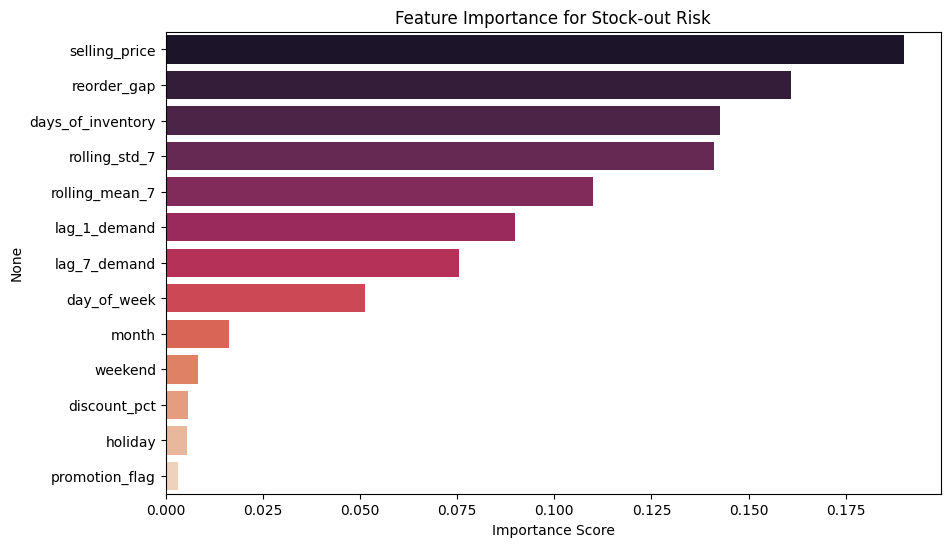

In [ ]:
importances = clf_model.feature_importances_
feat_imp = pd.Series(importances, index=features).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=feat_imp.values, y=feat_imp.index, palette='rocket')
plt.title('Feature Importance for Stock-out Risk')
plt.xlabel('Importance Score')
plt.show()

## 6. Save Predictions & Models for Round 3

In [ ]:
import joblib

# Save Models
joblib.dump(reg_model, '../models/demand_forecast_model.pkl')
joblib.dump(clf_model, '../models/stockout_risk_model.pkl')

# Save testing predictions to power the dashboard in Round 3
test_df.to_csv('../data/processed/model_predictions.csv', index=False)
print("SUCCESS: Models and Predictions saved!")

SUCCESS: Models and Predictions saved!
